In [128]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
from collections import defaultdict, deque
import random
import matplotlib.pyplot as plt

#**Sezione 0 - Setup ambiente**

# Guida: Setup dell'ambiente gym-idsgame

Questa guida aiuta a configurare correttamente l'ambiente **gym-idsgame** per il progetto di Cyber Security tramite Reinforcement Learning.

Il problema principale è che `gym-idsgame` è una libreria datata, scritta per versioni vecchie di OpenAI Gym. Non funziona out-of-the-box con le versioni moderne di Python e Gym/Gymnasium presenti su Google Colab. In questa guida si vedrà come risolvere il problema e ottenere un ambiente funzionante su cui implementare i vostri algoritmi (SARSA, DDQN, ecc.).

---

## 1. Installazione

Si installa `gym-idsgame` con `--no-deps` per evitare che tiri dentro dipendenze incompatibili (come versioni vecchie di gym, pyglet, ecc.). Le dipendenze necessarie (numpy, scikit-learn, torch) sono già presenti su Colab.

In [41]:
!pip install scikit-learn
!pip install --no-deps gym-idsgame

### Fix: import mancante nei bot agent

C'è un bug nella libreria: i file `random_attack_bot_agent.py` e `attack_maximal_value_bot_agent.py` usano `idsgame_util` senza importarlo, causando un `NameError` al primo `step()`. Lo si risolve con un monkey-patch: si inietta il modulo mancante nello scope dei bot agent.

Questo fix è necessario solo se l'ambiente decide di invocare internamente il bot agent. Nel seguente wrapper si passerà un placeholder (`-1`) come azione attaccante per evitare che il bot venga chiamato, ma il patch resta come rete di sicurezza.

In [42]:
import gym_idsgame.envs.util.idsgame_util as _idsgame_util
import gym_idsgame.agents.bot_agents.random_attack_bot_agent as _random_bot
import gym_idsgame.agents.bot_agents.attack_maximal_value_bot_agent as _maximal_bot

if not hasattr(_random_bot, 'idsgame_util'):
    _random_bot.idsgame_util = _idsgame_util
    print("Patch applicata: random_attack_bot_agent")

if not hasattr(_maximal_bot, 'idsgame_util'):
    _maximal_bot.idsgame_util = _idsgame_util
    print("Patch applicata: attack_maximal_value_bot_agent")

## 2. Il problema: perché gym-idsgame non funziona direttamente?

Se si prova a fare:

```python
import gym
env = gym.make('idsgame-random_attack-v0')
```

si otterrà un `AssertionError: The environment must specify an action space`.

Il motivo è che **gym-idsgame è un ambiente a 2 giocatori** (attaccante e difensore). Invece del classico `action_space` che gym si aspetta, espone:
- `attacker_action_space`
- `defender_action_space`

Il checker automatico di gym non trova `action_space` e crasha.

Inoltre, `reset()` e `step()` restituiscono tuple di tuple:
- `reset()` → `(attacker_obs, defender_obs)`
- `step()` → `((att_obs, def_obs), (att_reward, def_reward), done, info)`

Per usare l'ambiente con i classici algoritmi RL single-agent, bisogna scrivere un **wrapper** che:
1. Nasconda la complessità multi-agente
2. Esponga solo il punto di vista del difensore
3. Gestisca automaticamente l'attaccante

## 3. Due modi per creare l'ambiente

Ci sono due approcci validi. Si scelga quello che si preferisce.

### Approccio A: Istanziazione diretta (consigliato)

Si importi direttamente la classe dell'ambiente, senza passare da `gym.make()`:

```python
from gym_idsgame.envs import IdsGameRandomAttackV21Env
env = IdsGameRandomAttackV21Env()
```

### Approccio B: Tramite gym.make

Si aggiunga `disable_env_checker=True` per saltare il checker che causa l'errore:

```python
import gym
env = gym.make('idsgame-random_attack-v21', disable_env_checker=True)
```

In entrambi i casi, l'ambiente che si otterrà ha la stessa struttura e va wrappato.

## 4. Il DefenderWrapper

Questo wrapper trasforma l'ambiente multi-agente in un ambiente single-agent compatibile con qualsiasi algoritmo RL standard (SARSA, Q-Learning, DQN, DDQN, ecc.).

Cosa fa:
- Espone `action_space` = spazio azioni del difensore
- In `reset()`, restituisce solo l'osservazione del difensore (appiattita)
- In `step()`, attiva il bot attaccante passando un'azione valida e restituisce solo obs/reward del difensore

**Nota:** l'azione attaccante che si passa serve solo come "trigger" — il bot interno dell'ambiente decide autonomamente cosa fare. Passare `-1` disattiverebbe l'attaccante (reward sempre 0).

In [43]:
class DefenderWrapper:
    """
    Wrapper che adatta gym-idsgame per il single-agent (difensore).
    L'attaccante è gestito dal bot interno dell'ambiente.
    """
    def __init__(self, env):
        self.env = env
        self.action_space = env.defender_action_space

    def reset(self):
        obs = self.env.reset()
        # reset() restituisce (attacker_obs, defender_obs)
        if isinstance(obs, tuple):
            obs = obs[1]
        return obs.flatten()

    def step(self, action):
        # Passiamo un'azione qualsiasi (!= -1) per attivare il bot attaccante
        attacker_action = self.env.attacker_action_space.sample()
        res = self.env.step((attacker_action, action))

        obs, reward, done = res[0], res[1], res[2]
        info = res[3] if len(res) > 3 else {}

        # Estraiamo solo la parte del difensore
        if isinstance(obs, tuple):
            obs = obs[1]
        if isinstance(reward, tuple):
            reward = reward[1]

        return obs.flatten(), reward, done, info

## 5. Verifica: test che tutto funzioni

Si crei l'ambiente, si applichi il wrapper e si esegua qualche step con azioni casuali.

In [44]:
from gym_idsgame.envs import IdsGameRandomAttackV21Env, IdsGameMaximalAttackV21Env

# --- Random Attack ---
raw_env = IdsGameRandomAttackV21Env()
env = DefenderWrapper(raw_env)

obs = env.reset()
print(f"Osservazione iniziale: shape={obs.shape}, dtype={obs.dtype}")
print(f"Numero azioni difensore: {env.action_space.n}")

# Facciamo 5 step casuali
for i in range(5):
    action = env.action_space.sample()
    obs, reward, done, info = env.step(action)
    print(f"  Step {i+1}: reward={reward}, done={done}, obs_shape={obs.shape}")
    if done:
        break

print("\nRandom Attack: OK!")

Osservazione iniziale: shape=(20,), dtype=float64
Numero azioni difensore: 20
  Step 1: reward=0, done=False, obs_shape=(20,)
  Step 2: reward=0, done=False, obs_shape=(20,)
  Step 3: reward=0, done=False, obs_shape=(20,)
  Step 4: reward=0, done=False, obs_shape=(20,)
  Step 5: reward=0, done=False, obs_shape=(20,)

Random Attack: OK!


In [45]:
# --- Maximal Attack ---
raw_env_max = IdsGameMaximalAttackV21Env()
env_max = DefenderWrapper(raw_env_max)

obs = env_max.reset()
print(f"Osservazione iniziale: shape={obs.shape}, dtype={obs.dtype}")
print(f"Numero azioni difensore: {env_max.action_space.n}")

for i in range(5):
    action = env_max.action_space.sample()
    obs, reward, done, info = env_max.step(action)
    print(f"  Step {i+1}: reward={reward}, done={done}")
    if done:
        break

print("\nMaximal Attack: OK!")

Osservazione iniziale: shape=(20,), dtype=float64
Numero azioni difensore: 20
  Step 1: reward=0, done=False
  Step 2: reward=0, done=False
  Step 3: reward=0, done=False
  Step 4: reward=0, done=False
  Step 5: reward=0, done=False

Maximal Attack: OK!


## 6. Baseline: agente casuale

Prima di implementare SARSA o DDQN, è utile avere una baseline: quanto vince il difensore se agisce a caso? Questo serve come punto di riferimento per valutare se gli algoritmi che si implementati stanno effettivamente imparando qualcosa.

In [46]:
def random_baseline(env, n_episodes=500, max_steps=100):
    wins, losses = 0, 0
    total_rewards = []

    for _ in range(n_episodes):
        obs = env.reset()
        done = False
        ep_reward = 0
        steps = 0

        while not done and steps < max_steps:
            action = env.action_space.sample()
            obs, reward, done, info = env.step(action)
            ep_reward += reward
            steps += 1

        total_rewards.append(ep_reward)
        if ep_reward > 0:
            wins += 1
        elif ep_reward < 0:
            losses += 1

    print(f"Episodi: {n_episodes}")
    print(f"Vittorie difensore: {wins} ({wins/n_episodes*100:.1f}%)")
    print(f"Vittorie attaccante: {losses} ({losses/n_episodes*100:.1f}%)")
    print(f"Reward medio: {np.mean(total_rewards):.3f} ± {np.std(total_rewards):.3f}")

print("=== Baseline Random Attack ===")
env_ra = DefenderWrapper(IdsGameRandomAttackV21Env())
random_baseline(env_ra)

print("\n=== Baseline Maximal Attack ===")
env_ma = DefenderWrapper(IdsGameMaximalAttackV21Env())
random_baseline(env_ma)

=== Baseline Random Attack ===
Episodi: 500
Vittorie difensore: 0 (0.0%)
Vittorie attaccante: 241 (48.2%)
Reward medio: -12.526 ± 12.986

=== Baseline Maximal Attack ===
Episodi: 500
Vittorie difensore: 0 (0.0%)
Vittorie attaccante: 323 (64.6%)
Reward medio: -16.796 ± 12.433


## 7. Via all' implementazione

A questo punto si ha:
- L'ambiente installato e funzionante
- Un wrapper che dà un'interfaccia single-agent standard
- Una baseline casuale come riferimento

L'interfaccia del wrapper è quella classica di Gym:

```python
obs = env.reset()              # array numpy appiattito
obs, reward, done, info = env.step(action)  # action è un intero
n_actions = env.action_space.n # numero di azioni disponibili
```

Si potrà usarla direttamente con SARSA (convertendo `obs` in tupla per la Q-table) o con DDQN (convertendo `obs` in tensore PyTorch per la rete neurale).

**Buon lavoro!**

#**SECTION 1: SARSA**

In [62]:
obs = env.reset()
print(f"type: {type(obs)}/ shape: {obs.shape}/ dtype: {obs.dtype}")
print(f"Initial Observation: {obs}")

type: <class 'numpy.ndarray'>/ shape: (20,)/ dtype: float64
Initial Observation: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0.]


Shape Observation = 20

In [63]:
obs = env.reset()
done = False
t = 0
while not done and t < 15:
    action = env.action_space.sample()
    obs, reward, done, info = env.step(action)
    print(f"t={t:2d} | azione={action:2d} | reward={reward} | done={done}")
    print("        obs:", obs)
    t += 1

t= 0 | azione= 9 | reward=0 | done=False
        obs: [1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0.]
t= 1 | azione= 2 | reward=0 | done=False
        obs: [1. 1. 2. 1. 1. 1. 1. 1. 1. 2. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0.]
t= 2 | azione=19 | reward=0 | done=False
        obs: [1. 1. 2. 1. 1. 1. 1. 1. 1. 2. 1. 1. 1. 1. 1. 0. 0. 0. 0. 1.]
t= 3 | azione= 7 | reward=0 | done=False
        obs: [1. 1. 2. 1. 1. 1. 1. 2. 1. 2. 1. 1. 1. 1. 1. 0. 0. 0. 0. 1.]
t= 4 | azione=11 | reward=0 | done=False
        obs: [1. 1. 2. 1. 1. 1. 1. 2. 1. 2. 1. 2. 1. 1. 1. 0. 0. 0. 0. 1.]
t= 5 | azione= 6 | reward=0 | done=False
        obs: [1. 1. 2. 1. 1. 1. 2. 2. 1. 2. 1. 2. 1. 1. 1. 0. 0. 0. 0. 1.]
t= 6 | azione= 0 | reward=0 | done=True
        obs: [2. 1. 2. 1. 1. 1. 2. 2. 1. 2. 1. 2. 1. 1. 1. 0. 0. 0. 0. 1.]


L'effetto di un azione random scelta nello spazio delle azioni (da 0 a 19) è quello di aumentare di 1 il valore della rispettiva cella del vettore osservazione.

Es: Selezione random l'azione 19 --> Incremento +1 vettore Osservazione in posizione 19

In [64]:
visti = []
for _ in range(50):
    obs = env.reset()
    done = False
    while not done:
        obs, reward, done, info = env.step(env.action_space.sample())
        visti.append(obs)
visti = np.array(visti)
print("valore minimo visto:", visti.min())
print("valore massimo visto:", visti.max())
print("valori distinti che compaiono:", np.unique(visti))

valore minimo visto: 0.0
valore massimo visto: 4.0
valori distinti che compaiono: [0. 1. 2. 3. 4.]


Su 50 episodi i valori possibili usciti nelle varie osservazioni spannano valori da 0 a 4. 5 possibili valori.

La shape è 20. Quindi lo spazio degli stati possibili (guardando solo 50 episodi) è già molto grande: $$5^{20} \approx 95\,000\,000\,000\,000 \;\;(\approx 9{,}5 \times 10^{13})$$

Probabilmente lo spazio reale osservabile sarà molto minore perché la partita finisce prima. Ci si potrà allontanare dallo stato iniziale di pochissimo tenendo conto che l'effetto di un'azione random è incrementare di 1 il valore della cella.

In [78]:
def obs_to_state_A(obs):

  """Converte l'osservazione grezza nella chiave di stato per la Q-table (Strada A).

    Rappresentazione "grezza": l'osservazione viene usata integralmente, senza
    compressione. La conversione serve a due scopi distinti:
      - tuple(...)   -> rende lo stato hashable, requisito per usarlo come
                        chiave di un dizionario (un array NumPy non lo è);
      - .astype(int) -> rende l'identità dello stato esatta e stabile, evitando
                        che errori di virgola mobile generino stati "fantasma";
                        è lecito perché i valori dell'osservazione sono conteggi
                        interi.

    Args:
        obs: Osservazione dell'ambiente, array NumPy di 20 valori.

    Returns:
        tuple: Lo stato come tupla di 20 interi, usabile come chiave della Q-table.
  """

  return tuple(obs.astype(int))

In [69]:
def obs_to_state_B(obs):

  """Converte l'osservazione nella chiave di stato compressa (Strada B): tre feature.

    Args:
        obs: Osservazione dell'ambiente, array NumPy di 20 valori.

    Returns:
        tuple: (celle scoperte, difesa totale, difesa minima), tre interi.
    """

  count_zeros = int(np.sum(obs == 0))
  sum_defense = int(np.sum(obs))
  min_defense = int(np.min(obs))

  return (count_zeros, sum_defense,min_defense)

# Q-Table

In [70]:
n_actions = env.action_space.n
print(f"Action space lenght: {n_actions}")
Q = defaultdict(lambda:np.zeros(n_actions))

Action space lenght: 20


In [72]:
def select_action(env, state, f, epsilon):
    """Seleziona un'azione con politica ε-greedy (metodo tabellare, SARSA).

    Args:
        env: Ambiente, usato per campionare un'azione casuale quando esplora.
        state: Stato corrente, usato come chiave nella tabella dei valori.
        f: Tabella azione-valore (es. la Q-table): mappa ogni stato a un array
            di valori, uno per azione.
        epsilon: Probabilità di esplorazione, float in [0, 1].

    Returns:
        int: L'indice dell'azione scelta.
    """
    if np.random.rand() < epsilon:
        action = env.action_space.sample()     # esplora: azione casuale
    else:
        action = int(np.argmax(f[state]))      # sfrutta: azione col valore Q più alto nello stato
    return action

In [80]:
def train_sarsa(env, num_episodes, alpha, gamma, epsilon_start, epsilon_min, epsilon_decay, state_fn=obs_to_state_A):
    """Addestra un agente difensore con l'algoritmo SARSA (on-policy, tabellare).

    In ogni episodio l'agente interagisce con l'ambiente seguendo una politica
    ε-greedy e, dopo ogni passo, aggiorna una tabella azione-valore con la regola
    SARSA:  Q(s, a) ← Q(s, a) + α · [r + γ · Q(s', a') − Q(s, a)].
    Al termine di ogni episodio ε viene fatto decadere in modo moltiplicativo,
    fino a un minimo prefissato.

    Args:
        env: Ambiente, con reset(), step(action) e un action_space di n azioni.
        num_episodes: Numero di episodi di addestramento.
        alpha: Learning rate (ampiezza del passo), in [0, 1].
        gamma: Fattore di sconto in [0, 1], pesa le ricompense future.
        epsilon_start: Probabilità di esplorazione iniziale.
        epsilon_min: Valore sotto il quale ε non scende più.
        epsilon_decay: Fattore moltiplicativo applicato a ε a fine episodio.
        state_fn: Funzione che mappa l'osservazione grezza in una chiave di stato.
            Permette di usare lo stesso loop con lo stato grezzo (Strada A) o con
            lo stato a feature (Strada B).

    Returns:
        tuple: (Q, reward_history, wins_history, state_counts) — Q è la tabella
            azione-valore appresa (defaultdict stato → array di valori per azione),
            reward_history e wins_history sono reward totale e flag di vittoria per
            episodio (1 se reward > 0), state_counts conta le visite per stato.
    """
    n_actions = env.action_space.n
    Q = defaultdict(lambda: np.zeros(n_actions))     # Q-table: cresce pigramente, una riga per stato visitato
    state_counts = defaultdict(int)                  # visite per stato
    epsilon = epsilon_start
    reward_history = []
    wins_history = []

    for _ in range(num_episodes):

        ep_reward = 0
        done = False
        obs = env.reset()
        state = state_fn(obs)
        action = select_action(env, state, Q, epsilon)   # prima azione scelta FUORI dal ciclo

        while not done:

            next_obs, reward, done, info = env.step(action)
            next_state = state_fn(next_obs)
            next_action = select_action(env, next_state, Q, epsilon)   # a': azione che si giocherà davvero (on-policy)

            # target troncato allo stato terminale: a fine partita non c'è futuro da scontare
            if done:
                target = reward
            else:
                target = reward + gamma * Q[next_state][next_action]

            Q[state][action] += alpha * (target - Q[state][action])   # aggiornamento SARSA: passo verso il target
            state_counts[state] += 1

            state, action = next_state, next_action   # si trascina a' in avanti: diventa l'azione del passo dopo
            ep_reward += reward

        epsilon = max(epsilon_min, epsilon * epsilon_decay)   # decadimento di ε (pavimento a epsilon_min)
        reward_history.append(ep_reward)
        wins_history.append(int(ep_reward > 0))

    return Q, reward_history, wins_history, state_counts

In [130]:
def evaluate_sarsa(env, Q, epsilon, n_episodes=1000, state_fn=obs_to_state_A):
    """Valuta una politica SARSA già appresa, senza aggiornare Q.

    Gioca n_episodi con la Q-table fissata (tipicamente con epsilon=0, cioè
    solo sfruttamento) e riporta reward medio, tasso di vittoria e tasso di
    difese riuscite del difensore.

    Args:
        env: Ambiente su cui valutare.
        Q: Q-table appresa.
        epsilon: Probabilità di esplorazione in valutazione (0 = greedy puro).
        n_episodes: Numero di episodi di valutazione.
        state_fn: Rappresentazione dello stato; DEVE coincidere con quella usata
            in addestramento, altrimenti si cercano chiavi inesistenti.

    Returns:
        tuple: (reward medio, tasso di vittoria, tasso di difese riuscite).
    """
    reward_history = []
    wins_history = []
    defenses_history = []

    for _ in range(n_episodes):

        done = False
        ep_reward = 0
        obs = env.reset()
        state = state_fn(obs)
        action = select_action(env, state, Q, epsilon)

        while not done:
            next_obs, reward, done, info = env.step(action)
            next_state = state_fn(next_obs)
            next_action = select_action(env, next_state, Q, epsilon)

            state, action = next_state, next_action   # nessun aggiornamento di Q: qui si gioca soltanto
            ep_reward += reward

        # vittoria con bonus: il difensore ha rilevato l'attaccante dopo aver rinforzato tutto il nodo dati (reward > 0)
        wins_history.append(int(ep_reward > 0))

        # difesa riuscita: l'attaccante è stato rilevato, cioè il difensore ha vinto (reward >= 0);
        defenses_history.append(int(ep_reward >= 0))
        reward_history.append(ep_reward)

    average_reward = sum(reward_history) / len(reward_history)
    average_wins = sum(wins_history) / len(wins_history)
    average_defenses = sum(defenses_history) / len(defenses_history)
    print(f"Average Reward: {average_reward}")
    print(f"Average Wins: {average_wins}")
    print(f"Average Defenses: {average_defenses}")

    return average_reward, average_wins, average_defenses

In [75]:
def moving_average(data, window):
    return np.convolve(data, np.ones(window) / window, mode='valid')

In [76]:
def plot_moving_average(reward_history, wins_history):

  moving_reward = moving_average(reward_history,1000)
  moving_wins = moving_average(wins_history,1000)

  fig, ax = plt.subplots(1,2, figsize = (14,5))
  ax[0].plot(moving_reward)
  ax[0].set_xlabel("Episodes")
  ax[0].set_ylabel("Rewards")

  ax[1].plot(moving_wins)
  ax[1].set_xlabel("Episodes")
  ax[1].set_ylabel("Wins")
  ax[1].set_ylim(0, 1)

In [77]:
def plot_state_visits(counts, title="Distribuzione delle visite per stato (SARSA)"):
    """Disegna quante volte ogni stato distinto è stato visitato in addestramento.

    Args:
        counts: Dizionario che mappa ogni stato visitato al suo numero di visite,
            come restituito da train_sarsa (state_counts).
        title: Titolo mostrato sopra l'istogramma.
    """
    visits = list(counts.values())

    # --- statistiche ---
    total = len(visits)
    seen_once = sum(1 for c in visits if c == 1)
    print(f"Stati distinti totali: {total}")
    print(f"Stati visitati una sola volta: {seen_once} ({seen_once / total * 100:.1f}%)")
    print(f"Visite massime a un singolo stato: {max(visits)}")
    print(f"Mediana delle visite: {np.median(visits):.1f}")

    # --- istogramma ---
    plt.figure(figsize=(8, 5))
    plt.hist(visits, bins=50)
    plt.yscale('log')                    # la barra a 1-2 visite schiaccia il resto -> asse y logaritmico
    plt.xlabel("Numero di visite a uno stato")
    plt.ylabel("Numero di stati (scala log)")
    plt.title(title)
    plt.show()

In [85]:
def set_seed(seed=0):
    """Fissa il seed di random, numpy e torch per risultati riproducibili."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

#Training

## Rappresentazione dello stato: due approcci a confronto

SARSA è un metodo tabellare: conserva una stima di valore `Q(s, a)` per ogni stato incontrato. La scelta di come rappresentare lo stato è quindi decisiva, perché determina quanti stati distinti esistono e, di conseguenza, quante volte ciascuno può essere rivisitato e appreso. Un metodo tabellare, infatti, non impara uno stato che vede una sola volta.

Per questo motivo vengono messe a confronto due rappresentazioni alternative dello stesso ambiente:

- **Approccio A, stato grezzo:** l'osservazione completa (i 20 valori di difesa) usata direttamente come chiave della tabella. Nessuna informazione viene persa, ma lo spazio degli stati è enorme e non si satura mai.
- **Approccio B, stato a feature:** l'osservazione viene compressa in tre caratteristiche sintetiche, cioè celle scoperte, difesa totale e difesa minima. Gli stati distinti crollano e situazioni simili vengono apprese insieme, al prezzo di una minore ricchezza di dettaglio.

L'obiettivo del confronto è verificare quale delle due rappresentazioni permette all'agente tabellare di imparare meglio. Il ragionamento che ne emerge, comprimere l'informazione per guadagnare in copertura e generalizzazione, è uno dei risultati centrali di questa sezione.

### Approccio A, rappresentazione grezza dello stato

Si parte dall'Approccio A. Lo stato coincide con l'osservazione completa dell'ambiente: la tupla dei 20 valori di difesa, usata così com'è. Questa scelta conserva tutta l'informazione disponibile, ma genera uno spazio degli stati enorme, in cui oltre il 48% delle configurazioni viene incontrato una sola volta durante l'addestramento: troppo poco perché il metodo tabellare possa formare stime di valore affidabili.

In [86]:
set_seed(0)

env_sarsa = DefenderWrapper(IdsGameRandomAttackV21Env())

Q, reward_history, wins_history, state_counts = train_sarsa(
    env_sarsa,
    num_episodes=20000,
    alpha=0.1,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_min=0.01,
    epsilon_decay=0.999,
    state_fn = obs_to_state_A
)

print("Completed Episodes:", len(reward_history))
print("Visited distinct states:", len(Q))
print("Average reward on the last 100 episodes:", np.mean(reward_history[-100:]))

Completed Episodes: 20000
Visited distinct states: 20877
Average reward on the last 100 episodes: -10.91


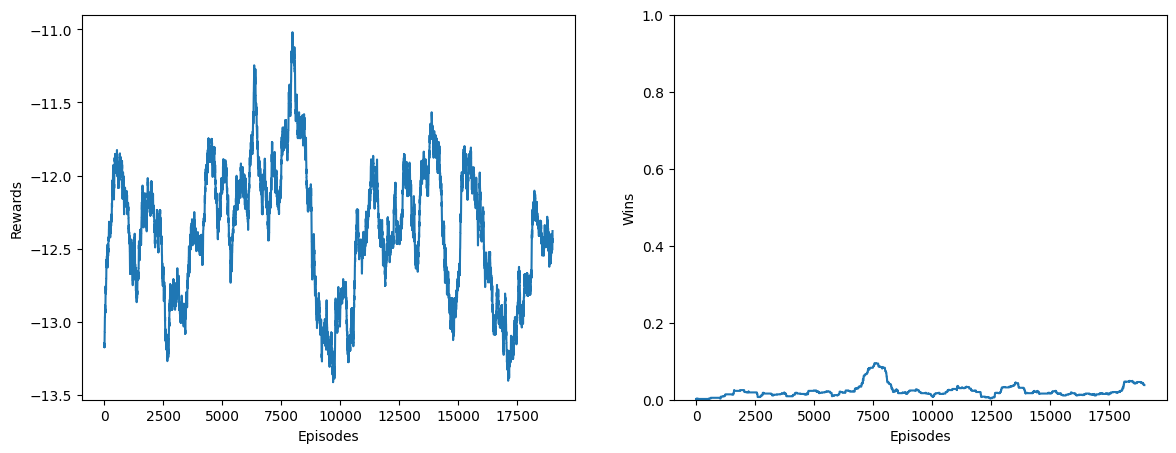

In [87]:
plot_moving_average(reward_history, wins_history)

In [126]:
set_seed(0)
average_rewar_eps_zero, average_wins_eps_zero, average_defenses_eps_zero = evaluate_sarsa(env_sarsa, Q, 0, n_episodes= 2000)

Average Reward: -12.649
Average Wins: 0.0
Average Defenses: 0.5135


Stati distinti totali: 17766
Stati visitati una sola volta: 8669 (48.8%)
Visite massime a un singolo stato: 20000
Mediana delle visite: 2.0


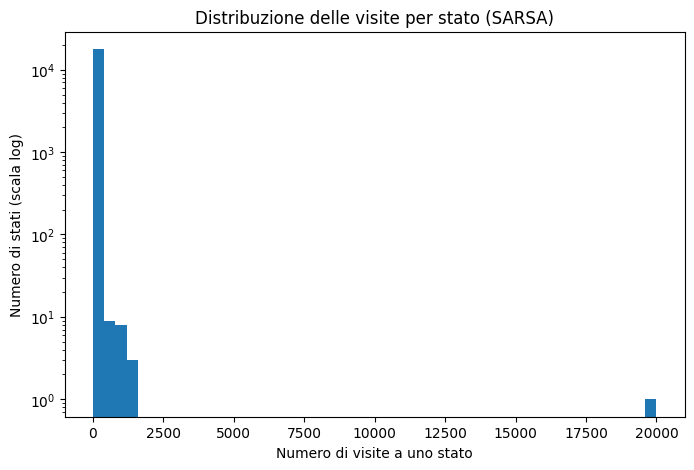

In [92]:
plot_state_visits(state_counts)

### Risultati dell'Approccio A

Con la rappresentazione grezza l'agente non impara in modo misurabile. In valutazione greedy ottiene un reward medio di −12,65 e un tasso di difese riuscite del 51,4%, praticamente identici alla baseline casuale (−12,53 e 51,8%). La curva di addestramento lo conferma: oscilla tra circa −13,4 e −11 senza una tendenza crescente e termina intorno a −12,5, cioè al livello del difensore casuale.

L'istogramma delle visite spiega perché. Gli stati in cui l'agente ha agito sono 17.766: quasi la metà (48,8%) è stata visitata una sola volta e la mediana è di appena 2 visite. Solo lo stato iniziale, comune a tutti gli episodi, è visitato 20.000 volte. La maggior parte delle stime di valore si basa quindi su una o due osservazioni.

Va precisato come questo si traduce in valutazione. Poiché l'osservazione dipende solo dalle azioni del difensore, la politica greedy percorre sempre la stessa catena di stati. Quando la catena entra in uno stato mai aggiornato, con tutti i valori a zero, `argmax` sceglie sempre l'azione 0, non un'azione casuale. Il risultato dipende quindi da quale sequenza di azioni la tabella finisce per codificare, e con stime così poco consolidate questa sequenza non è migliore di una casuale.

### Approccio B, rappresentazione dello stato per feature

Si passa ora all'Approccio B. Lo stato non è più l'osservazione completa, ma una sua sintesi in tre caratteristiche interpretabili: il numero di celle scoperte (quelle a valore zero), la difesa totale accumulata e la difesa minima presente. Molte osservazioni diverse vengono così ricondotte alla stessa chiave, e questo ha due effetti combinati: lo spazio degli stati si riduce drasticamente, e ogni stato viene rivisitato molte più volte, rendendo l'apprendimento più stabile. Il prezzo da pagare è che situazioni distinte, ma con le stesse tre feature, vengono trattate come un unico stato: una generalizzazione più aggressiva, che guadagna in copertura ciò che perde in ricchezza di dettaglio.

In [93]:
set_seed(0)

Q_b, reward_history_b, wins_history_b, state_counts_b = train_sarsa(
    env_sarsa,
    num_episodes=20000,
    alpha=0.1,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_min=0.01,
    epsilon_decay=0.999,
    state_fn = obs_to_state_B
)

print("Completed Episodes:", len(reward_history_b))
print("Visited distinct states:", len(Q_b))
print("Average reward on the last 100 episodes:", np.mean(reward_history_b[-100:]))

Completed Episodes: 20000
Visited distinct states: 137
Average reward on the last 100 episodes: -6.47


In [127]:
set_seed(0)
average_rewar_eps_zero, average_wins_eps_zero, average_defenses_eps_zero = evaluate_sarsa(env_sarsa,Q_b,0,n_episodes= 2000, state_fn = obs_to_state_B)

Average Reward: -6.7145
Average Wins: 0.153
Average Defenses: 0.7315


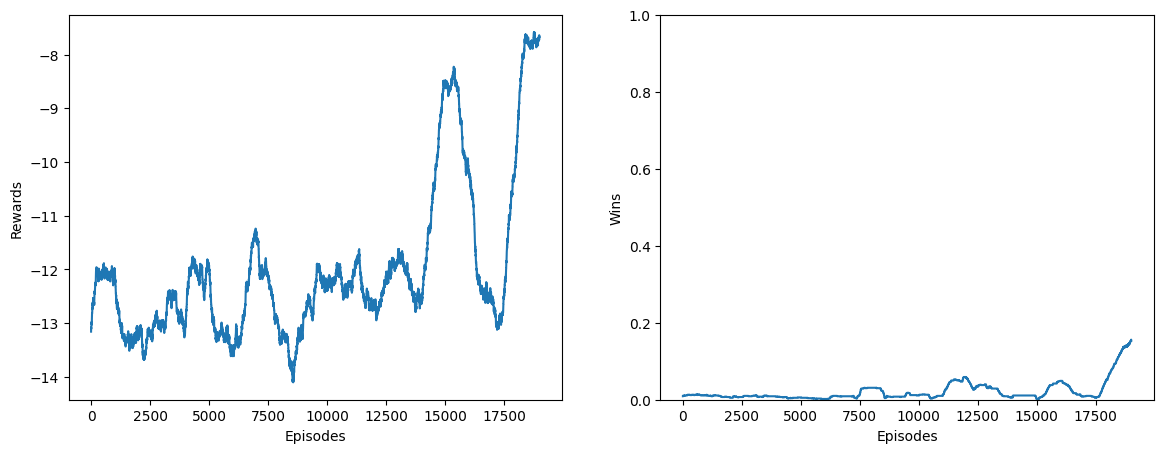

In [95]:
plot_moving_average(reward_history_b, wins_history_b)

Stati distinti totali: 132
Stati visitati una sola volta: 10 (7.6%)
Visite massime a un singolo stato: 20000
Mediana delle visite: 55.0


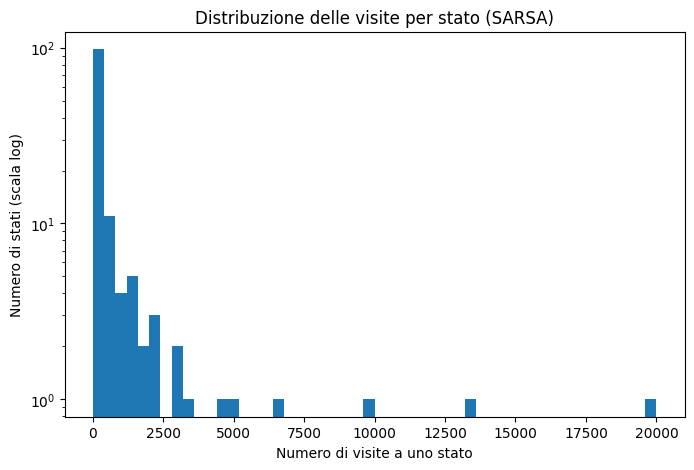

In [96]:
plot_state_visits(state_counts_b)

### Risultati dell'Approccio B

In questa esecuzione la politica greedy raggiunge un reward medio di −6,71, un tasso di difese riuscite del 73,2% e il 15,3% di vittorie con bonus: un miglioramento netto rispetto alla baseline (51,8%).

L'istogramma delle visite è ribaltato rispetto all'Approccio A: 132 stati distinti, solo il 7,6% visto una volta, mediana di 55 visite. Dal punto di vista della copertura, la compressione funziona.

Il risultato però non va letto come stabile. La curva di addestramento resta piatta tra −12 e −14, il livello del caso, per circa 14.000 episodi. Verso l'episodio 15.000 sale fino a circa −8,3 e poi ricade a −13. Solo negli ultimi 2.000 episodi risale a circa −7,7. Il reward in valutazione coincide con quello di fine addestramento perché la valutazione fotografa proprio quell'ultimo momento: se l'addestramento si fosse fermato all'episodio 17.000, il risultato sarebbe stato vicino al caso. Il tuning della sezione successiva lo conferma: ripetendo la stessa configurazione su altre tre esecuzioni, il risultato torna al livello del difensore casuale.

La copertura degli stati è quindi una condizione necessaria ma non sufficiente: con feature che non distinguono le difese del nodo dati, la tabella può oscillare tra politiche buone e cattive.

## Ottimizzazione degli iperparametri: lo schedule di esplorazione

Si prosegue con l'Approccio B, che nell'esecuzione singola ha dato il risultato migliore, e si prova a tarare il modo in cui l'esplorazione diminuisce nel corso dell'addestramento. Poiché SARSA è un metodo on-policy, impara il valore della stessa politica con cui agisce: la strategia di esplorazione non è un dettaglio, ma influenza direttamente ciò che l'agente apprende. Per questo l'ottimizzazione si concentra proprio su questo aspetto.

L'iperparametro oggetto del tuning è il fattore di decadimento di epsilon (epsilon_decay), cioè la velocità con cui la probabilità di esplorazione scende dal valore iniziale fino al minimo. Tutti gli altri iperparametri restano fissi (alpha e gamma), così che l'unica variabile a cambiare sia lo schedule di esplorazione e il confronto risulti pulito. La tensione da bilanciare è nota: un decadimento troppo rapido fa smettere di esplorare troppo presto, bloccando l'agente su strategie mediocri; un decadimento troppo lento impedisce di sfruttare ciò che si è imparato, perché l'agente continua a muoversi a caso.

Per ogni valore candidato, la procedura addestra un nuovo agente e ne valuta la politica in modalità greedy (epsilon = 0). Dato che i risultati dipendono dal seme casuale, come osservato in precedenza, ogni configurazione viene ripetuta su più esecuzioni indipendenti e se ne media reward e tasso di vittoria: così il confronto riflette la prestazione tipica di ciascuno schedule, non un singolo caso fortunato o sfortunato.

In [97]:
def tune_sarsa_epsilon_decay(env, decay_values, n_runs=3,
                             num_episodes=20000, alpha=0.1, gamma=0.95,
                             epsilon_start=1.0, epsilon_min=0.01,
                             state_fn=obs_to_state_B, eval_episodes=2000):
    """Ottimizza il decadimento di epsilon per SARSA (Approccio B).

    Per ogni valore candidato di epsilon_decay addestra un agente da zero,
    ripetendo l'addestramento su n_runs esecuzioni indipendenti per attenuare
    la variabilità dovuta al seme casuale, valuta ogni politica in modalità
    greedy (epsilon = 0) e registra reward medio e tasso di vittoria medio.

    Args:
        env: Ambiente di addestramento e valutazione.
        decay_values: Valori di epsilon_decay da testare.
        n_runs: Esecuzioni indipendenti per valore, su cui si media.
        num_episodes, alpha, gamma, epsilon_start, epsilon_min: iperparametri
            di SARSA, tenuti fissi così che vari solo il decadimento.
        state_fn: Rappresentazione dello stato (qui l'Approccio B).
        eval_episodes: Episodi usati da ogni valutazione greedy.

    Returns:
        dict: {decay: {"reward": reward_medio, "wins": win_rate_medio}}.
    """
    results = {}
    for decay in decay_values:
        rewards, wins = [], []
        for _ in range(n_runs):
            # agente nuovo a ogni run: l'unica cosa che cambia tra configurazioni è 'decay'
            Q, _, _, _ = train_sarsa(
                env, num_episodes, alpha, gamma,
                epsilon_start, epsilon_min, decay, state_fn=state_fn,
            )
            # valutazione greedy (epsilon=0): misura la politica, non l'esplorazione
            r, w = evaluate_policy(env, Q, 0, n_episodes=eval_episodes, state_fn=state_fn)
            rewards.append(r)
            wins.append(w)
        # media sulle n_runs: riflette la prestazione tipica, non un singolo seme
        results[decay] = {"reward": np.mean(rewards), "wins": np.mean(wins)}
        print(f"decay={decay}: reward={np.mean(rewards):.2f}, win-rate={np.mean(wins):.3f}")
    return results

In [98]:
def plot_tuning(results):
    """Disegna reward greedy e tasso di vittoria in funzione di epsilon_decay."""
    decays = sorted(results.keys())
    rewards = [results[d]["reward"] for d in decays]
    wins = [results[d]["wins"] for d in decays]
    x = [str(d) for d in decays]        # etichette testuali: i valori restano spaziati in modo uniforme

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(x, rewards, marker="o")
    ax[0].set_xlabel("epsilon_decay")
    ax[0].set_ylabel("Reward medio (greedy)")
    ax[0].set_title("Reward in funzione del decadimento di ε")

    ax[1].plot(x, wins, marker="o")
    ax[1].set_xlabel("epsilon_decay")
    ax[1].set_ylabel("Tasso di vittoria (greedy)")
    ax[1].set_ylim(0, 1)
    ax[1].set_title("Tasso di vittoria in funzione del decadimento di ε")

    plt.tight_layout()
    plt.show()

Average Reward: -6.4395
Average Wins: 0.019
Average Reward: -9.076
Average Wins: 0.2835
Average Reward: -8.787
Average Wins: 0.341
decay=0.99: reward=-8.10, win-rate=0.214
Average Reward: -13.3765
Average Wins: 0.0005
Average Reward: -8.833
Average Wins: 0.0035
Average Reward: -15.0145
Average Wins: 0.0
decay=0.995: reward=-12.41, win-rate=0.001
Average Reward: -11.9855
Average Wins: 0.0005
Average Reward: -14.729
Average Wins: 0.0
Average Reward: -13.585
Average Wins: 0.0
decay=0.999: reward=-13.43, win-rate=0.000
Average Reward: -7.3685
Average Wins: 0.351
Average Reward: -8.729
Average Wins: 0.096
Average Reward: -10.6325
Average Wins: 0.089
decay=0.9995: reward=-8.91, win-rate=0.179
Average Reward: -12.857
Average Wins: 0.0
Average Reward: -9.425
Average Wins: 0.0
Average Reward: -12.2005
Average Wins: 0.005
decay=0.9999: reward=-11.49, win-rate=0.002


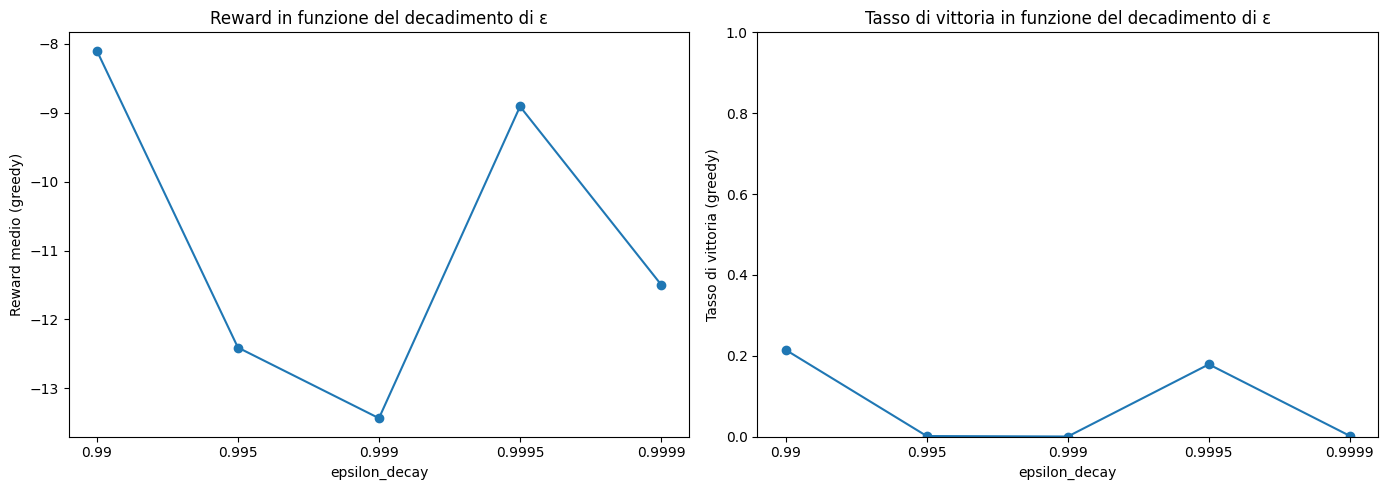

In [99]:
set_seed(0)
decay_values = [0.99, 0.995, 0.999, 0.9995, 0.9999]
results = tune_sarsa_epsilon_decay(env_sarsa, decay_values, n_runs=3)
plot_tuning(results)

### Risultati del tuning

| epsilon_decay | Reward medio (3 run) | Reward dei singoli run | Vittorie con bonus (media) |
|---|---|---|---|
| 0,99 | −8,10 | −6,44 / −9,08 / −8,79 | 21,4% |
| 0,995 | −12,41 | −13,38 / −8,83 / −15,01 | 0,1% |
| 0,999 | −13,43 | −11,99 / −14,73 / −13,59 | 0,0% |
| 0,9995 | −8,91 | −7,37 / −8,73 / −10,63 | 17,9% |
| 0,9999 | −11,49 | −12,86 / −9,43 / −12,20 | 0,2% |

Il "win-rate" stampato da questa cella corrisponde alle vittorie con bonus (reward > 0).

Il tuning non mostra una tendenza legata alla velocità di decadimento. I due valori migliori, 0,99 e 0,9995, sono rispettivamente il più rapido e il secondo più lento, mentre lo 0,995, anch'esso rapido, è tra i peggiori. Con tre run per valore e una dispersione così ampia (per 0,99 le vittorie con bonus vanno dall'1,9% al 34,1%; per 0,995 il reward va da −15,0 a −8,8), le differenze tra configurazioni non sono distinguibili dal rumore.

Il dato più importante è un altro. Il decadimento 0,999 è esattamente la configurazione usata per l'Approccio B nella sezione precedente. Nelle tre nuove esecuzioni dà un reward medio di −13,4, che corrisponde a circa il 48% di difese riuscite (−13,4 / −26 ≈ 52% di sconfitte), cioè al livello del difensore casuale. Il −6,7 ottenuto in precedenza era quindi un'esecuzione favorevole, non il comportamento tipico.

Come configurazione indicativa si segnala 0,99, che ha la media migliore. Questa scelta però non è statisticamente distinguibile dalle altre, e non è stata riaddestrata né usata nella tabella finale.

## Sezione 1, SARSA: sintesi e analisi

### Rappresentazione dello stato e copertura

SARSA è un metodo tabellare, quindi la rappresentazione dello stato decide quante volte ogni stato può essere rivisitato. Con lo stato grezzo (Approccio A) l'agente agisce in 17.766 stati distinti, quasi la metà visitati una sola volta (mediana 2 visite). Con le tre feature (Approccio B) gli stati scendono a 132, con una mediana di 55 visite. La compressione risolve il problema della copertura.

### Prestazioni

L'Approccio A non migliora sul difensore casuale: 51,4% di difese riuscite contro il 51,8% della baseline, con una curva di addestramento piatta.

L'Approccio B ha prodotto, in un'esecuzione, il 73,2% di difese riuscite e un reward di −6,7. Ripetendo la stessa configurazione nel tuning, però, tre esecuzioni su tre tornano al livello del caso (reward medio −13,4, circa 48% di difese riuscite). Anche la curva di addestramento dell'esecuzione riportata mostra che il buon risultato compare solo negli ultimi episodi, dopo un picco già raggiunto e perso intorno all'episodio 15.000. Il risultato di B è quindi possibile ma non affidabile.

### Perché

Due proprietà dell'ambiente spiegano questo comportamento:
- l'osservazione dipende solo dalle azioni del difensore e non contiene informazioni sull'attaccante, quindi una politica greedy esegue sempre la stessa sequenza di azioni;
- le feature di B misurano in pratica il tempo trascorso e le mosse sprecate sul nodo START, non lo stato delle difese del nodo dati. Molte storie diverse condividono la stessa chiave, e le stime di valore oscillano.

### Conclusioni

| | Reward (greedy) | Difese riuscite | Vittorie con bonus |
|---|---|---|---|
| Baseline casuale | −12,5 | 51,8% | 0% |
| Approccio A (stato grezzo) | −12,6 | 51,4% | 0% |
| Approccio B, esecuzione riportata | −6,7 | 73,2% | 15,3% |
| Approccio B, stessa configurazione, 3 run del tuning | −13,4 | ≈ 48% (stimato dal reward) | 0% |

La compressione dello stato è necessaria perché un metodo tabellare possa imparare qualcosa, ma con queste feature non basta a renderlo affidabile. I passi successivi naturali sarebbero una rappresentazione basata sulle difese del nodo dati e una valutazione su più semi. Il tuning dell'esplorazione non ha mostrato differenze distinguibili dal rumore.

Questi limiti motivano la seconda parte del progetto, in cui una rete neurale (Double DQN) riceve l'osservazione grezza e approssima la funzione Q senza bisogno di una tabella né di feature costruite a mano. Il limite dell'osservabilità, però, resta lo stesso anche per il DDQN.

#**SECTION 2: DDQN**

In [101]:
class QNetwork(nn.Module):
    """Rete che approssima la funzione Q per il DDQN.

    Riceve un'osservazione (o un batch di osservazioni) e restituisce un
    valore Q per ciascuna azione, in un'unica passata. È un MLP a due strati
    nascosti con attivazione ReLU; l'uscita è lineare, perché i valori Q sono
    numeri reali qualsiasi, non probabilità (nessuna softmax o attivazione finale).

    Args:
        input_dim: Dimensione dell'osservazione (qui 20, lo stato grezzo).
        n_actions: Numero di azioni, cioè la dimensione dell'uscita (qui 20).
        hidden_dim: Numero di neuroni dei due strati nascosti.
    """

    def __init__(self, input_dim, n_actions, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, n_actions)   # uscita: un Q-value per azione

    def forward(self, x):
        # x: (batch_size, input_dim) -> (batch_size, n_actions)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)        # nessuna attivazione finale: i Q-value sono reali, anche negativi
        return x

In [102]:
class ReplayBuffer:
    """Buffer di esperienze a capacità fissa per RL off-policy.

    Conserva le transizioni passate (state, action, reward, next_state, done) e
    restituisce mini-batch casuali per l'addestramento. Il campionamento casuale
    rompe la correlazione temporale tra transizioni consecutive, mentre la
    capacità fissa rende il buffer una finestra scorrevole che scarta
    automaticamente le esperienze più vecchie quando è pieno.
    """

    def __init__(self, capacity):
        """Crea un buffer vuoto.

        Args:
            capacity: Numero massimo di transizioni conservate; le più vecchie
                vengono scartate oltre questo limite.
        """
        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """Memorizza una transizione nel buffer.

        Args:
            state: Osservazione prima dell'azione.
            action: Azione eseguita (int).
            reward: Ricompensa ricevuta.
            next_state: Osservazione dopo l'azione.
            done: Se l'episodio è terminato a questo passo.
        """
        # maxlen della deque: oltre la capacità, la transizione più vecchia esce da sola
        self.memory.append((state, action, reward, next_state, done))

    def __len__(self):
        """Restituisce il numero di transizioni attualmente memorizzate."""
        return len(self.memory)

    def sample(self, batch_size):
        """Restituisce un mini-batch casuale, raggruppato campo per campo.

        Args:
            batch_size: Numero di transizioni da estrarre.

        Returns:
            tuple: (states, actions, rewards, next_states, dones), ciascuno una
                tupla di lunghezza batch_size. I valori sono oggetti Python/NumPy
                grezzi; la conversione in tensori è lasciata all'agente.
        """
        batch = random.sample(self.memory, batch_size)
        # zip(*batch) "ruota" la lista di transizioni in gruppi per campo:
        # da [(s,a,r,s',d), ...] a (s,s,...), (a,a,...), ...
        states, actions, rewards, next_states, dones = zip(*batch)
        return states, actions, rewards, next_states, dones

In [103]:
class DDQNAgent:
    """Agente Double Deep Q-Network (DDQN) per il difensore.

    Usa una rete neurale al posto della Q-table per approssimare la funzione Q,
    e apprende off-policy da esperienze passate pescate da un replay buffer.
    Mantiene due reti: una "online", aggiornata a ogni passo, e una "target",
    copia congelata che fornisce un bersaglio stabile e viene risincronizzata
    periodicamente. Il target è calcolato in stile Double DQN: la rete online
    sceglie l'azione migliore nello stato successivo, la rete target ne valuta
    il valore, così da ridurre la sovrastima tipica del DQN classico.
    """

    def __init__(self,
                 input_dim,
                 n_actions,
                 gamma=0.95,
                 lr=0.001,
                 batch_size=64,
                 buffer_capacity=10000,
                 epsilon_start=1.0,
                 epsilon_min=0.01,
                 epsilon_decay=0.999,
                 target_update_freq=1):
        """Inizializza reti, ottimizzatore, buffer e iperparametri.

        Args:
            input_dim: Dimensione dell'osservazione grezza (qui 20).
            n_actions: Numero di azioni (qui 20).
            gamma: Fattore di sconto.
            lr: Learning rate dell'ottimizzatore Adam.
            batch_size: Dimensione del mini-batch per ogni aggiornamento.
            buffer_capacity: Capacità massima del replay buffer.
            epsilon_start, epsilon_min, epsilon_decay: schedule di esplorazione.
            target_update_freq: Ogni quanti episodi la rete target viene
                risincronizzata con la online.
        """
        # --- iperparametri ---
        self.gamma = gamma
        self.batch_size = batch_size
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.epsilon = epsilon_start          # tasso di esplorazione corrente (decade nel tempo)
        self.target_update_freq = target_update_freq
        self.n_actions = n_actions

        # --- due reti: la online si allena a ogni passo, la target è una copia congelata ---
        self.q_net = QNetwork(input_dim, n_actions)
        self.target_net = QNetwork(input_dim, n_actions)
        # la target parte come copia esatta dei pesi della online
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.target_net.eval()                # mai allenata direttamente: solo copiata dalla online

        # l'ottimizzatore aggiorna SOLO i parametri della rete online
        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)

        # replay buffer: separa l'apprendimento dall'ordine di raccolta delle esperienze
        self.buffer = ReplayBuffer(buffer_capacity)

    def select_action(self, state, epsilon=None):
        """Sceglie un'azione con politica ε-greedy usando la rete online.

        Args:
            state: Osservazione corrente (array NumPy di forma (input_dim,)).
            epsilon: Valore usato solo per questa chiamata (es. 0 per una
                valutazione greedy); se None, usa l'epsilon corrente dell'agente.

        Returns:
            int: L'indice dell'azione scelta.
        """
        # valore temporaneo per questa sola chiamata (non sovrascrive self.epsilon)
        eps = epsilon if epsilon is not None else self.epsilon

        if random.random() < eps:
            # esplora: azione casuale (basta il numero di azioni, non serve l'ambiente)
            return random.randrange(self.n_actions)

        # sfrutta: chiede alla rete online i Q-value di questo stato.
        # (1, input_dim): la rete si aspetta un batch, un singolo stato è un batch da 1
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():                 # solo inferenza: non costruisce il grafo dei gradienti
            q_values = self.q_net(state_tensor)
        return q_values.argmax(dim=1).item()  # azione migliore, come intero Python

    def update(self):
        """Esegue un passo di apprendimento su un mini-batch pescato dal buffer.

        Calcola la predizione Q(s, a) con la rete online e il bersaglio in stile
        Double DQN, dove la rete online SCEGLIE l'azione migliore in s' e la rete
        target la VALUTA: y = r + γ · Q_target(s', argmax_a' Q_online(s', a')),
        azzerando il termine futuro sugli stati terminali. Minimizza l'errore
        quadratico medio tra predizione e bersaglio aggiornando la sola rete online.

        Returns:
            float | None: Il valore della loss del passo, oppure None se il buffer
                non conteneva ancora abbastanza transizioni per aggiornare.
        """
        # 1. guardia: serve esperienza sufficiente per formare un batch
        if len(self.buffer) < self.batch_size:
            return None

        # 2. campiona un batch di transizioni passate
        states, actions, rewards, next_states, dones = self.buffer.sample(self.batch_size)

        # 3. conversione in tensori (B = batch_size)
        states = torch.tensor(np.array(states), dtype=torch.float32)       # (B, 20)
        actions = torch.tensor(actions, dtype=torch.long)                  # (B,)  long: faranno da indici
        rewards = torch.tensor(rewards, dtype=torch.float32)               # (B,)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32)  # (B, 20)
        dones = torch.tensor(dones, dtype=torch.float32)                   # (B,)  float: usato nell'aritmetica del target

        # 4. predizione: Q(s, a) per le azioni realmente eseguite (gather = una colonna per riga)
        q_pred = self.q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)   # (B,)

        # 5. bersaglio Double DQN (nessun gradiente: il target è una costante)
        with torch.no_grad():
            actions_online = self.q_net(next_states).argmax(dim=1)              # la ONLINE sceglie a* in s'
            q_next = self.target_net(next_states).gather(                       # la TARGET valuta a*
                1, actions_online.unsqueeze(1)).squeeze(1)                      # (B,)
            q_target = rewards + self.gamma * q_next * (1 - dones)              # (B,) futuro azzerato sui terminali

        # 6. loss: errore quadratico medio tra predizione e bersaglio
        loss = nn.functional.mse_loss(q_pred, q_target)

        # 7. passo di discesa del gradiente sulla sola rete online
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()   # loss del passo (numero Python), per tracciarne l'andamento

    def update_target(self):
        """Risincronizza la rete target copiando i pesi della rete online."""
        self.target_net.load_state_dict(self.q_net.state_dict())

    def train(self, env, num_episodes):
        """Addestra l'agente per un numero di episodi, raccogliendo le metriche.

        Args:
            env: Ambiente con reset() e step(action).
            num_episodes: Numero di episodi di addestramento.

        Returns:
            tuple: (reward_history, wins_history, loss_history) — reward totale e
                flag di vittoria (1 se reward > 0) per ogni episodio, e la loss di
                ogni passo in cui c'è stato un effettivo aggiornamento.
        """
        reward_history = []
        wins_history = []
        loss_history = []

        for episode in range(num_episodes):

            state = env.reset()
            done = False
            ep_reward = 0

            while not done:
                action = self.select_action(state)                 # sceglie sullo stato corrente (ogni passo)
                next_state, reward, done, info = env.step(action)
                self.buffer.push(state, action, reward, next_state, done)   # archivia, non impara subito

                loss = self.update()                               # un passo di apprendimento (se il buffer è pronto)
                if loss is not None:                               # salta i passi iniziali col buffer ancora magro
                    loss_history.append(loss)

                state = next_state
                ep_reward += reward

            # a fine episodio: decadimento di ε e sincronizzazione periodica della target
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)
            if (episode + 1) % self.target_update_freq == 0:
                self.update_target()

            reward_history.append(ep_reward)
            wins_history.append(int(ep_reward > 0))

        return reward_history, wins_history, loss_history

In [131]:
def evaluate_ddqn(agent, env, epsilon, n_episodes=2000):
    """Valuta un agente DDQN già addestrato, senza aggiornarlo.

    Gioca n_episodi usando la rete dell'agente (tipicamente con epsilon=0, cioè
    solo sfruttamento) e riporta reward medio e tasso di vittoria del difensore.
    Non memorizza transizioni e non esegue aggiornamenti: qui l'agente gioca soltanto.

    Args:
        agent: Agente DDQN addestrato.
        env: Ambiente su cui valutare.
        epsilon: Probabilità di esplorazione in valutazione (0 = greedy puro).
        n_episodes: Numero di episodi di valutazione.

    Returns:
        tuple: (reward medio, tasso di vittoria).
    """
    reward_history = []
    wins_history = []
    defenses_history = []

    for _ in range(n_episodes):

        done = False
        ep_reward = 0
        state = env.reset()

        while not done:
            action = agent.select_action(state, epsilon)   # sceglie sullo stato corrente, ogni passo
            next_state, reward, done, info = env.step(action)
            state = next_state
            ep_reward += reward

        reward_history.append(ep_reward)
        wins_history.append(int(ep_reward > 0)) # vittoria con bonus: il difensore ha rilevato l'attaccante dopo aver rinforzato tutto il nodo dati (reward > 0)
        defenses_history.append(int(ep_reward >= 0)) # difesa riuscita: l'attaccante è stato rilevato, cioè il difensore ha vinto (reward >= 0);


    average_reward = sum(reward_history) / len(reward_history)
    average_wins = sum(wins_history) / len(wins_history)
    average_defenses = sum(defenses_history) / len(defenses_history)
    print(f"Average Reward: {average_reward}")
    print(f"Average Wins: {average_wins}")
    print(f"Average Defenses: {average_defenses}")

    return average_reward, average_wins, average_defenses

#DDQN RANDOM ATTACK

In [106]:
set_seed(0)
agent = DDQNAgent(input_dim=20, n_actions=20)
env_ddqn = DefenderWrapper(IdsGameRandomAttackV21Env())
rewards_ddqn, wins_ddqn, loss_ddqn = agent.train(env_ddqn, num_episodes=20000)

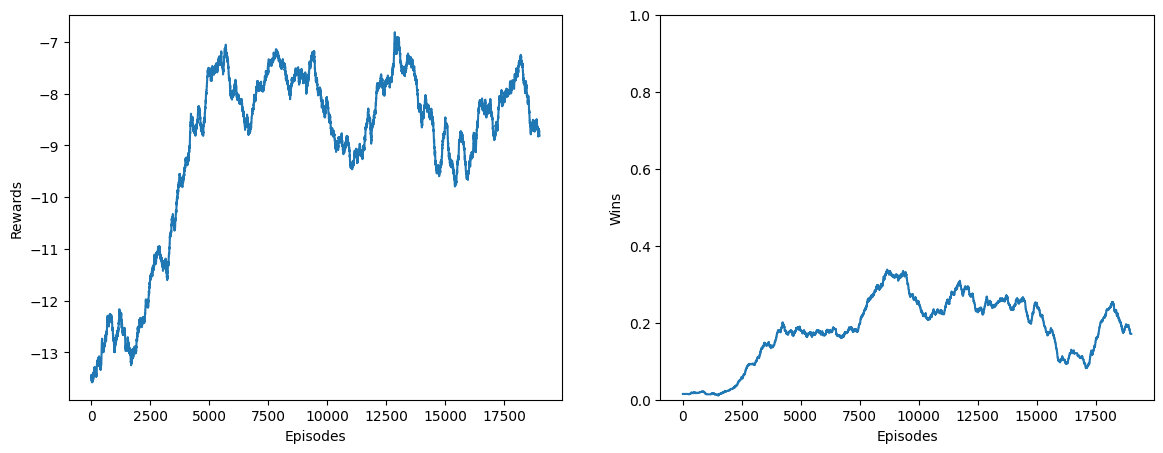

In [107]:
plot_moving_average(rewards_ddqn, wins_ddqn)

In [117]:
set_seed(0)
average_reward, average_wins, average_defenses= evaluate_ddqn(agent,env_ddqn,epsilon =0)

Average Reward: -7.8
Average Wins: 0.0
Average Defenses: 0.7


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


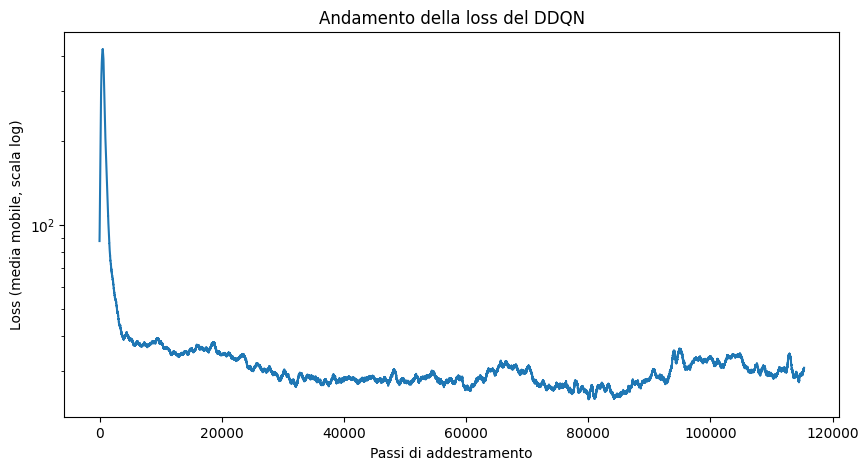

In [109]:
plt.figure(figsize=(10, 5))
plt.plot(moving_average(loss_ddqn, 500))
plt.yscale('log')
plt.xlabel("Passi di addestramento")
plt.ylabel("Loss (media mobile, scala log)")
plt.title("Andamento della loss del DDQN")
plt.show()

In [118]:
#variabilità con il seed
set_seed(42)
agent2 = DDQNAgent(input_dim=20, n_actions=20, target_update_freq=1)
env2 = DefenderWrapper(IdsGameRandomAttackV21Env())
agent2.train(env2, num_episodes=10000)   # 10k basta per vedere la tendenza
evaluate_ddqn(agent2, env2, 0, n_episodes=2000)

Average Reward: -10.3805
Average Wins: 0.3315
Average Defenses: 0.5745


(np.float64(-10.3805), 0.3315, 0.5745)

### DDQN sullo scenario Random Attack

Con il DDQN la curva di reward in addestramento sale da circa −14 a un livello intorno a −8 dopo circa 5.000 episodi, ma resta comunque oscillante. La loss crolla rapidamente dopo i primi passi e si assesta su un livello basso e un pò rumoroso.

In valutazione greedy (seed 0) l'agente ottiene un reward medio di −7,8, il 70% di difese riuscite e lo 0% di vittorie con bonus. Il 70% è il vero tasso di vittoria del difensore, contro il 51,8% della baseline: un miglioramento di circa 18 punti. Lo 0% di vittorie con bonus significa che, quando il difensore vince, non ha ancora rinforzato tutte e quattro le difese del nodo dati. Non indica un comportamento "di pareggio", perché in questo ambiente il pareggio non esiste.

Un'esecuzione con un seme diverso (seed 42, addestrata per 10.000 episodi invece di 20.000) ha dato un reward di −10,4, il 57,5% di difese riuscite e il 33,2% di vittorie con bonus. Le due politiche sono diverse: la prima vince più spesso; la seconda vince meno spesso ma, quando vince, ha più spesso rinforzato tutto il nodo dati. Il reward premia la prima (−7,8 contro −10,4), perché ogni sconfitta costa circa −26 mentre il bonus vale pochi punti.

Le due esecuzioni però non bastano ad attribuire la differenza al seme, perché differiscono anche per la durata dell'addestramento. Inoltre, nella curva di training del seed 0, il tasso di vittorie con bonus oscilla tra 0 e circa il 50% all'interno della stessa esecuzione. Il tipo di politica ottenuta sembra dipendere soprattutto dal momento in cui ci si ferma: la politica non è convergente.

#DDQN MAXIMAL ATTACK

In [119]:
set_seed(0)
agent_max = DDQNAgent(input_dim=20, n_actions=20, target_update_freq=1)
env_max = DefenderWrapper(IdsGameMaximalAttackV21Env())
rewards_max, wins_max, logs_max = agent_max.train(env_max, num_episodes=20000)
evaluate_ddqn(agent_max, env_max, 0)

Average Reward: -2.21
Average Wins: 0.0
Average Defenses: 0.915


(np.float64(-2.21), 0.0, 0.915)

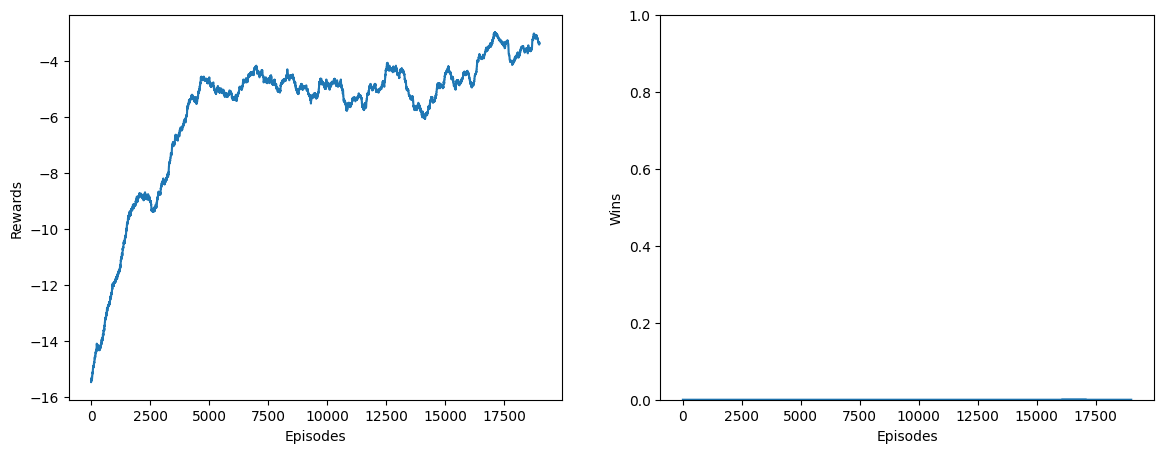

In [120]:
plot_moving_average(rewards_max, wins_max)

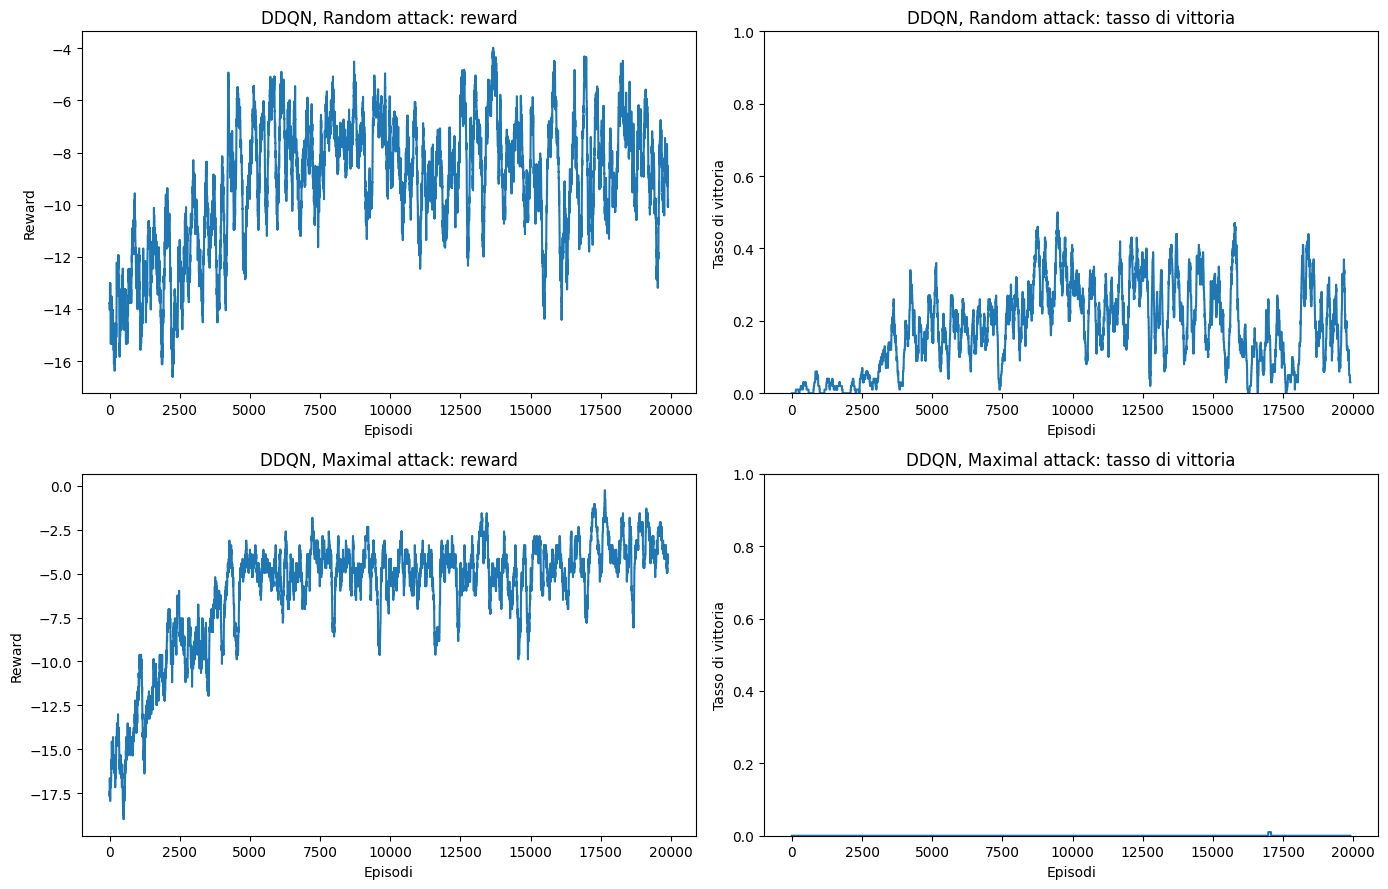

In [121]:

# --- Curve di training DDQN affiancate ---
w = 100
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# riga 0: random_attack
ax[0, 0].plot(moving_average(rewards_ddqn, w))
ax[0, 0].set_title("DDQN, Random attack: reward")
ax[0, 0].set_xlabel("Episodi"); ax[0, 0].set_ylabel("Reward")

ax[0, 1].plot(moving_average(wins_ddqn, w))
ax[0, 1].set_title("DDQN, Random attack: tasso di vittoria")
ax[0, 1].set_xlabel("Episodi"); ax[0, 1].set_ylabel("Tasso di vittoria"); ax[0, 1].set_ylim(0, 1)

# riga 1: maximal_attack
ax[1, 0].plot(moving_average(rewards_max, w))
ax[1, 0].set_title("DDQN, Maximal attack: reward")
ax[1, 0].set_xlabel("Episodi"); ax[1, 0].set_ylabel("Reward")

ax[1, 1].plot(moving_average(wins_max, w))
ax[1, 1].set_title("DDQN, Maximal attack: tasso di vittoria")
ax[1, 1].set_xlabel("Episodi"); ax[1, 1].set_ylabel("Tasso di vittoria"); ax[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### DDQN sullo scenario Maximal Attack

Contro l'attaccante maximal il DDQN ottiene il risultato migliore del progetto. La curva di reward sale da circa −17 a un plateau tra −3 e −5 dopo circa 5.000 episodi. In valutazione greedy l'agente ottiene un reward medio di −2,21 e il 91,5% di difese riuscite, contro il 35,4% del difensore casuale: vince più di nove partite su dieci contro l'attaccante più forte.

Lo 0% di vittorie con bonus non significa che l'attaccante maximal sia imbattibile. Significa solo che il difensore lo rileva prima di aver alzato tutte e quattro le difese del nodo dati.

Il difensore vince più spesso contro il maximal (91,5%) che contro il random (70%). Una spiegazione plausibile sta nel funzionamento dell'attaccante maximal, che non è un avversario ottimo. Prima esegue una ricognizione dei nodi, poi attacca il punto che la ricognizione indica come più debole. Partendo da difese tutte uguali, il bersaglio è prevedibile, e la ricognizione fotografa una situazione che il difensore può cambiare subito dopo. Ogni attacco fallito dà al difensore una possibilità di rilevamento. L'attaccante random, invece, non segue uno schema, e una sequenza di difese fissa non può anticiparlo. L'ipotesi andrebbe verificata registrando le azioni dell'attaccante e la sequenza greedy appresa dal difensore.

Il risultato si riferisce a una sola esecuzione e andrebbe confermato su più semi.

## Conclusioni finali

Il progetto ha confrontato un metodo tabellare on-policy (SARSA) e un metodo di deep reinforcement learning off-policy (Double DQN) nel ruolo di difensore in gym-idsgame (v21). Lo studio del codice dell'ambiente ha mostrato che un episodio finisce solo con il rilevamento dell'attaccante (vittoria del difensore, reward ≥ 0) o con la compromissione del nodo dati (sconfitta, reward ≈ −26). L'indicatore principale è quindi il tasso di difese riuscite, che coincide con il tasso di vittoria del difensore. Le vittorie con bonus (reward > 0) contano solo le vittorie ottenute dopo aver rinforzato tutto il nodo dati.

### Quadro complessivo

| Scenario | Agente | Reward | Difese riuscite (vittorie) | Vittorie con bonus | Esecuzioni |
|---|---|---|---|---|---|
| Random | Baseline casuale | −12,5 | 51,8% | 0% | 1 (500 episodi) |
| Random | SARSA A (grezzo) | −12,6 | 51,4% | 0% | 1 |
| Random | SARSA B (feature) | −6,7 | 73,2% | 15,3% | 1 |
| Random | SARSA B, stessa configurazione nel tuning | −13,4 | ≈ 48% (stimato) | 0% | media di 3 |
| Random | DDQN (seed 0) | −7,8 | 70,0% | 0% | 1 |
| Random | DDQN (seed 42, 10k episodi) | −10,4 | 57,5% | 33,2% | 1 |
| Maximal | Baseline casuale | −16,8 | 35,4% | 0% | 1 (500 episodi) |
| Maximal | DDQN | −2,2 | 91,5% | 0% | 1 |

SARSA non è stato eseguito sullo scenario Maximal.

### Cosa mostrano i risultati

**Il DDQN contro l'attaccante maximal** è il risultato più netto: dal 35,4% al 91,5% di vittorie, con una curva di apprendimento regolare. Va confermato su più semi.

**Contro l'attaccante random** entrambi i metodi possono superare il caso (73% SARSA B, 70% DDQN, contro il 51,8%), ma nessuno dei due in modo affidabile. SARSA A non impara. SARSA B torna al livello del caso in tre esecuzioni su tre con la stessa configurazione. Il DDQN oscilla tra politiche diverse all'interno della stessa esecuzione. Con un'esecuzione per metodo non è possibile stabilire quale dei due sia migliore su questo scenario.

**La rappresentazione dello stato** è decisiva per il metodo tabellare: comprimere 20 valori in 3 feature risolve il problema della copertura (da 17.766 a 132 stati). Le feature scelte, però, misurano in pratica il tempo trascorso e le mosse sprecate sul nodo START, non lo stato delle difese che contano, e questo ne limita l'affidabilità.

### Limiti

- **Osservabilità.** L'osservazione del difensore dipende solo dalle sue azioni e non contiene informazioni sull'attaccante. Una politica greedy esegue quindi sempre la stessa sequenza di azioni: il problema si riduce di fatto alla ricerca di una buona sequenza fissa, e né la tabella né la rete possono reagire a ciò che fa l'avversario. Questo ridimensiona, in questo specifico ambiente, il vantaggio del DDQN legato alla rappresentazione appresa.
- **Variabilità.** Quasi tutti i risultati vengono da una sola esecuzione, e dove ne sono disponibili più d'una la dispersione è ampia.
- **Iperparametri del DDQN.** Non sono stati tarati; in particolare, la rete target sincronizzata a ogni episodio (circa 6 passi) offre poca stabilizzazione.

### Sintesi

Entrambi gli approcci possono trasformare un difensore casuale in uno che vince la maggioranza delle partite, e il DDQN contro l'attaccante maximal lo fa in modo netto. Contro l'attaccante random, però, i risultati dipendono fortemente dall'esecuzione e dal momento in cui ci si ferma.